In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from linearmodels.panel import PanelOLS
import re
import numpy as np

In [2]:
# CPS occupation
OCC_COL = 'OCC'
# CPS age
AGE_COL = 'AGE'
# Young/Entry Workers Column
Y_COL = '18_25'
# CPS weight  
WEIGHT_COL    = 'WTFINL'                  
# Scores occupation       
INDEX_OCC_COL = 'CPS Code'
# All score columns
INDEX_COLS = ['alpha', 'beta', 'gamma']
Z_COLS = ['alpha_z', 'beta_z', 'gamma_z']

In [3]:
df_q_raw = pd.read_csv('../data/checkpoints/df_q.csv')
df_h_raw = pd.read_csv('../data/checkpoints/df_h.csv')

passing_occ = pd.read_json('../data/checkpoints/passing_occs.json')

month_filter    = passing_occ.loc[passing_occ['window'] == 'monthly', 'OCC']
quarter_filter  = passing_occ.loc[passing_occ['window'] == 'quarterly', 'OCC']
biannual_filter = passing_occ.loc[passing_occ['window'] == 'half-year', 'OCC']
year_filter     = passing_occ.loc[passing_occ['window'] == 'year', 'OCC']

In [ ]:
# Construct quarterly and biannual panel by filtering from occupations that passsed at biannual level
df_q = df_q_raw[df_q_raw['OCC'].isin(biannual_filter)]
panel_q = df_q.groupby(['OCC', 'QUARTER']).agg(
    N=(AGE_COL, 'size'),
    np=(Y_COL, 'sum'),
    **{col: (col, 'first') for col in Z_COLS},
    **{col: (col, 'first') for col in INDEX_COLS},
).reset_index()
panel_q['Y_SHARE'] = panel_q['np'] / panel_q['N']

df_h = df_h_raw[df_h_raw['OCC'].isin(biannual_filter)]
panel_h = df_h.groupby(['OCC', 'HALF_YEAR']).agg(
    N=(AGE_COL, 'size'),
    np=(Y_COL, 'sum'),
    **{col: (col, 'first') for col in Z_COLS},
    **{col: (col, 'first') for col in INDEX_COLS}
).reset_index()
panel_h['Y_SHARE'] = panel_h['np'] / panel_h['N']

In [ ]:
# Create quintile bins of treatment intensity
windows = {'QUARTER': panel_q,
           'HALF_YEAR': panel_h}

for window, panel_w in windows.items():
    for col in INDEX_COLS:
        panel_w[f"{col}_quintile"] = pd.qcut(panel_w[col], q=5, labels=False)

quintile_labels = {
    0: 'Quintile 1 (Lowest)',
    1: 'Quintile 2',
    2: 'Quintile 3',
    3: 'Quintile 4',
    4: 'Quintile 5 (Highest)',
}

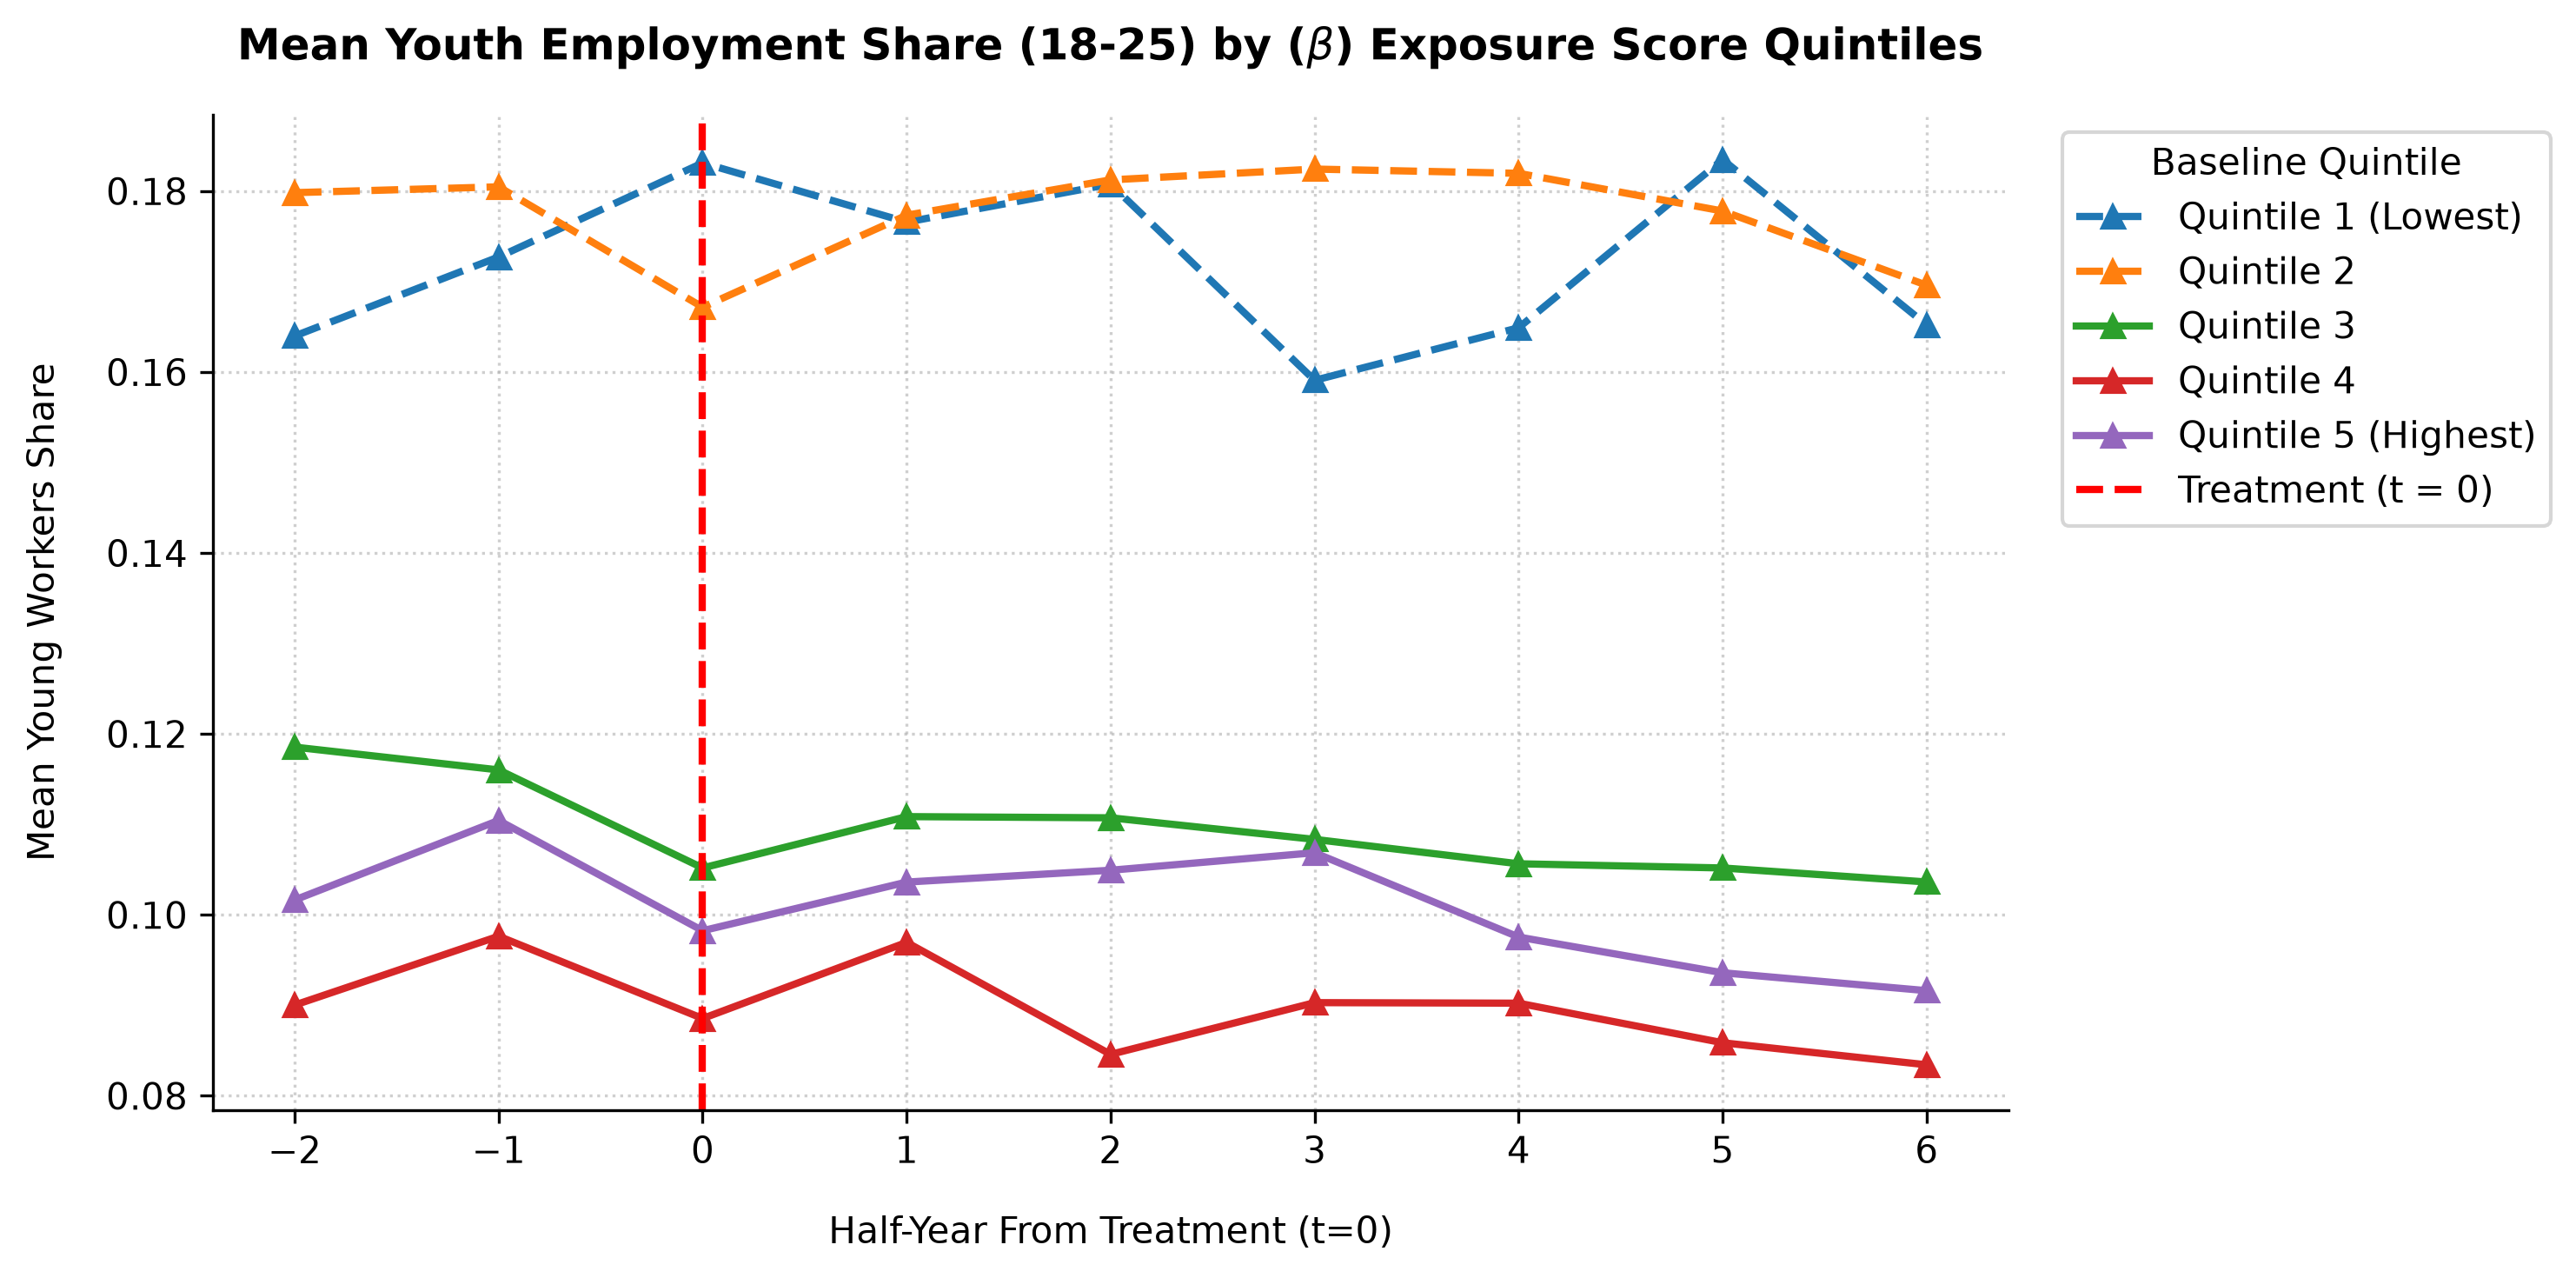

In [ ]:
# Quintiles pre trend eyecheck (half year)
fig, ax = plt.subplots(figsize=(10, 5), dpi=300)
grouped_h = panel_h.groupby(['HALF_YEAR', 'beta_quintile'])['Y_SHARE'].mean().unstack()
grouped_h = grouped_h.rename(columns=quintile_labels)

styles = ['--', '--', '-', '-', '-']

for i, col in enumerate(grouped_h.columns):
  ax.plot(
      grouped_h.index,
      grouped_h[col],
      label=str(quintile_labels.get(col, col)),  # Safely looks up integer keys
      linestyle=styles[i],
      linewidth=2,
      marker='^'
  )
ax.set_title(r"Mean Youth Employment Share (18-25) by ($\beta$) Exposure Score Quintiles",
             pad=15,
             fontsize=12,
             fontweight='bold')

ax.axvline(
    x=0, color='red', linestyle='--', linewidth=2, label='Treatment (t = 0)'
)

ax.set_xlabel('Half-Year From Treatment (t=0)', labelpad=12)
ax.set_ylabel('Mean Young Workers Share', labelpad=12)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_xticks(panel_h['HALF_YEAR'].unique())

ax.legend(
    title='Baseline Quintile',
    bbox_to_anchor=(1.02, 1),
    loc='upper left',
    frameon=True,
)

ax.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

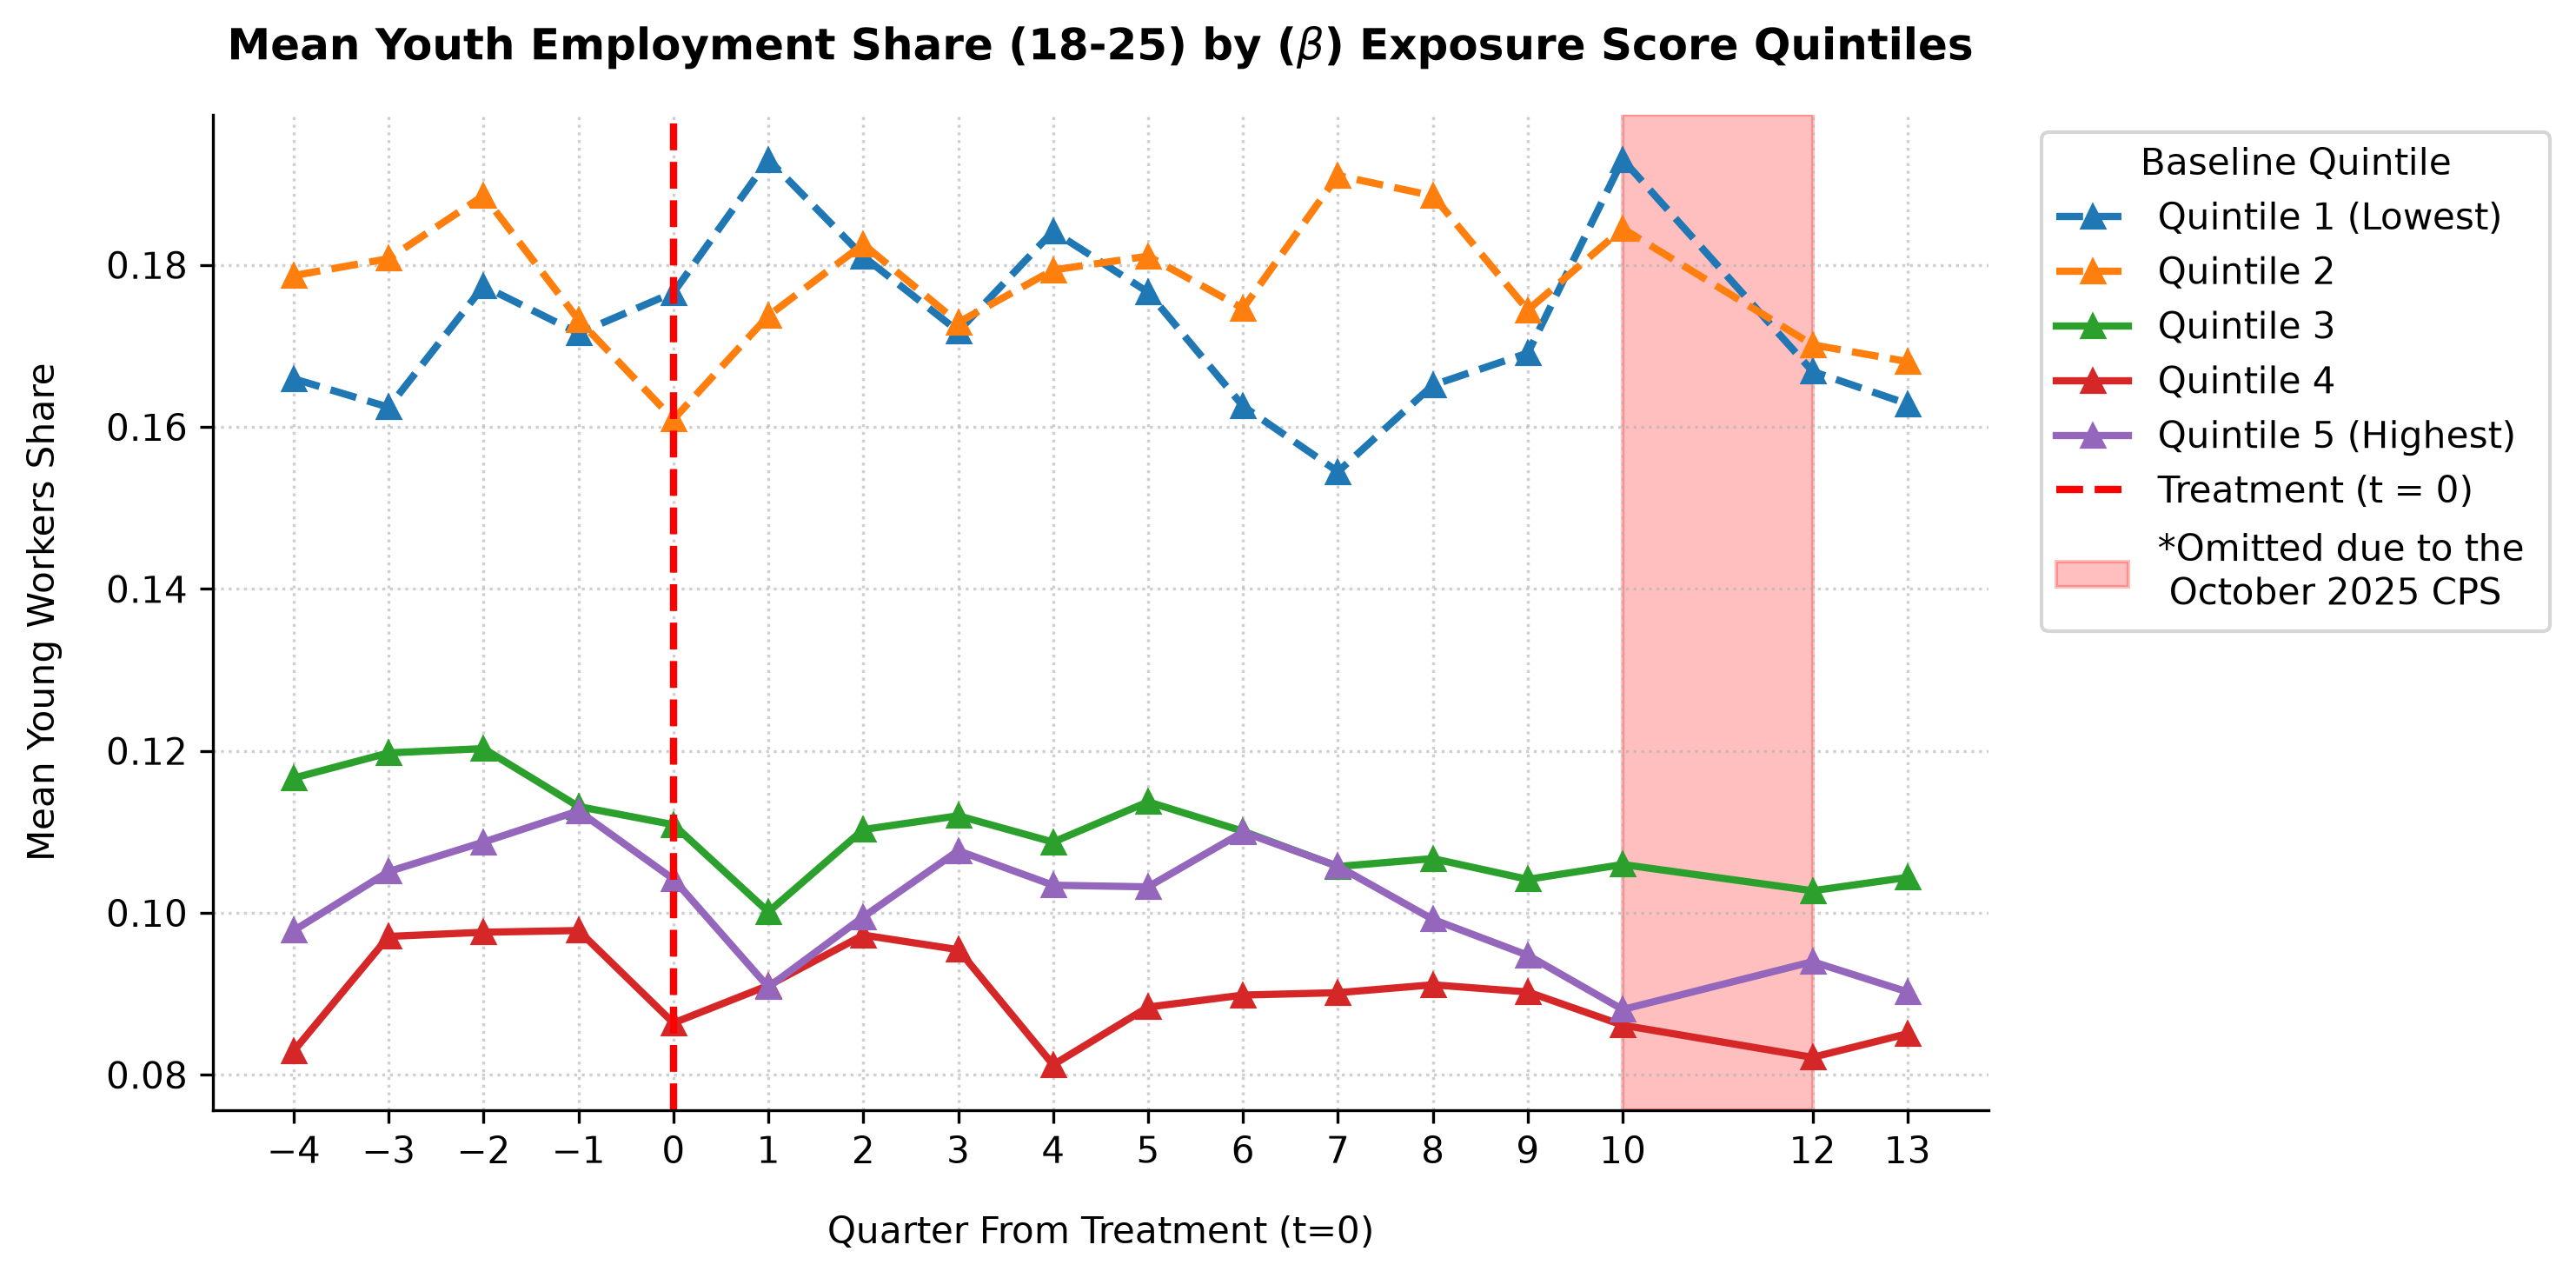

In [ ]:
# Quintiles pre trend eyecheck (Quarter)
fig, ax = plt.subplots(figsize=(10, 5), dpi=300)
grouped_q = panel_q.groupby(['QUARTER', 'beta_quintile'])['Y_SHARE'].mean().unstack()
grouped_q = grouped_q.rename(columns=quintile_labels)

styles = ['--', '--', '-', '-', '-']

for i, col in enumerate(grouped_q.columns):
  ax.plot(
      grouped_q.index,
      grouped_q[col],
      label=str(quintile_labels.get(col, col)),  # Safely looks up integer keys
      linestyle=styles[i],
      linewidth=2,
      marker='^'
  )

ax.set_title(r"Mean Youth Employment Share (18-25) by ($\beta$) Exposure Score Quintiles",
             pad=15,
             fontsize=12,
             fontweight='bold')

ax.axvline(
    x=0, color='r', linestyle='--', linewidth=2, label='Treatment (t = 0)'
)
ax.axvspan(10, 12, color='r', alpha=0.25, label='*Omitted due to the \n October 2025 CPS')

ax.set_xlabel('Quarter From Treatment (t=0)', labelpad=12)
ax.set_ylabel('Mean Young Workers Share', labelpad=12)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_xticks(sorted(panel_q['QUARTER'].unique()))

ax.legend(
    title='Baseline Quintile',
    bbox_to_anchor=(1.02, 1),
    loc='upper left',
    frameon=True,
)
ax.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

In [ ]:
# Create dataframe with quarter level dummies for event study
df_pre = panel_q.set_index(['OCC', 'QUARTER'], drop=False)
df_event = pd.get_dummies(df_pre, columns=['QUARTER'], drop_first=False, dtype=int)
df_event = df_event.drop(columns=['QUARTER_-1'])


In [ ]:
# Construct dummies and event study regression formua
quarter_dummies = [c for c in df_event.columns if c.startswith('QUARTER_')]

formula = "Y_SHARE ~"
interaction_terms = ' + '.join([f'beta:Q("{d}")' for d in quarter_dummies])
formula = f"Y_SHARE ~ {interaction_terms} + EntityEffects + TimeEffects"

Y = df_event['Y_SHARE']
X = df_event['beta_z']

print(formula)


Y_SHARE ~ beta:Q("QUARTER_-4") + beta:Q("QUARTER_-3") + beta:Q("QUARTER_-2") + beta:Q("QUARTER_0") + beta:Q("QUARTER_1") + beta:Q("QUARTER_2") + beta:Q("QUARTER_3") + beta:Q("QUARTER_4") + beta:Q("QUARTER_5") + beta:Q("QUARTER_6") + beta:Q("QUARTER_7") + beta:Q("QUARTER_8") + beta:Q("QUARTER_9") + beta:Q("QUARTER_10") + beta:Q("QUARTER_12") + beta:Q("QUARTER_13") + EntityEffects + TimeEffects


In [ ]:
# Estimate event study coefficients and save
mod_event = PanelOLS.from_formula(formula, data=df_event, weights=df_event['N'])
res_event = mod_event.fit(cov_type='clustered', cluster_entity=True)
print(res_event.summary)

df_res = pd.DataFrame({
    'coef': res_event.params,
    'lower': res_event.conf_int()['lower'],
    'upper': res_event.conf_int()['upper']
})

                          PanelOLS Estimation Summary                           
Dep. Variable:                Y_SHARE   R-squared:                        0.0059
Estimator:                   PanelOLS   R-squared (Between):             -0.0353
No. Observations:                6069   R-squared (Within):              -0.0100
Date:                Tue, Jul 28 2026   R-squared (Overall):             -0.0347
Time:                        02:54:47   Log-likelihood                 1.413e+04
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      2.1090
Entities:                         357   P-value                           0.0060
Avg Obs:                       17.000   Distribution:                 F(16,5680)
Min Obs:                       17.000                                           
Max Obs:                       17.000   F-statistic (robust):             1.5758
                            

In [ ]:
# Reorganize to reinsert omitted variable
df_res['quarter'] = [int(re.search(r'(-?\d+)', s).group(1)) for s in df_res.index]
baseline = pd.DataFrame({'coef': 0.0, 'lower': 0.0, 'upper': 0.0, 'quarter': -1}, index=[-1])
df_res = pd.concat([df_res, baseline]).sort_values('quarter').reset_index(drop=True)
print(df_res)

        coef     lower     upper  quarter
0  -0.001221 -0.015876  0.013433       -4
1   0.008272 -0.006391  0.022936       -3
2  -0.007074 -0.020238  0.006090       -2
3   0.000000  0.000000  0.000000       -1
4  -0.011069 -0.026672  0.004533        0
5  -0.016670 -0.033502  0.000163        1
6  -0.016947 -0.034647  0.000754        2
7  -0.009979 -0.026765  0.006807        3
8  -0.017583 -0.034014 -0.001151        4
9  -0.015224 -0.034273  0.003825        5
10 -0.012463 -0.032973  0.008047        6
11 -0.007979 -0.024041  0.008083        7
12 -0.013516 -0.029133  0.002101        8
13 -0.013469 -0.029142  0.002203        9
14 -0.030716 -0.053416 -0.008015       10
15 -0.018320 -0.035539 -0.001101       12
16 -0.019766 -0.036263 -0.003269       13


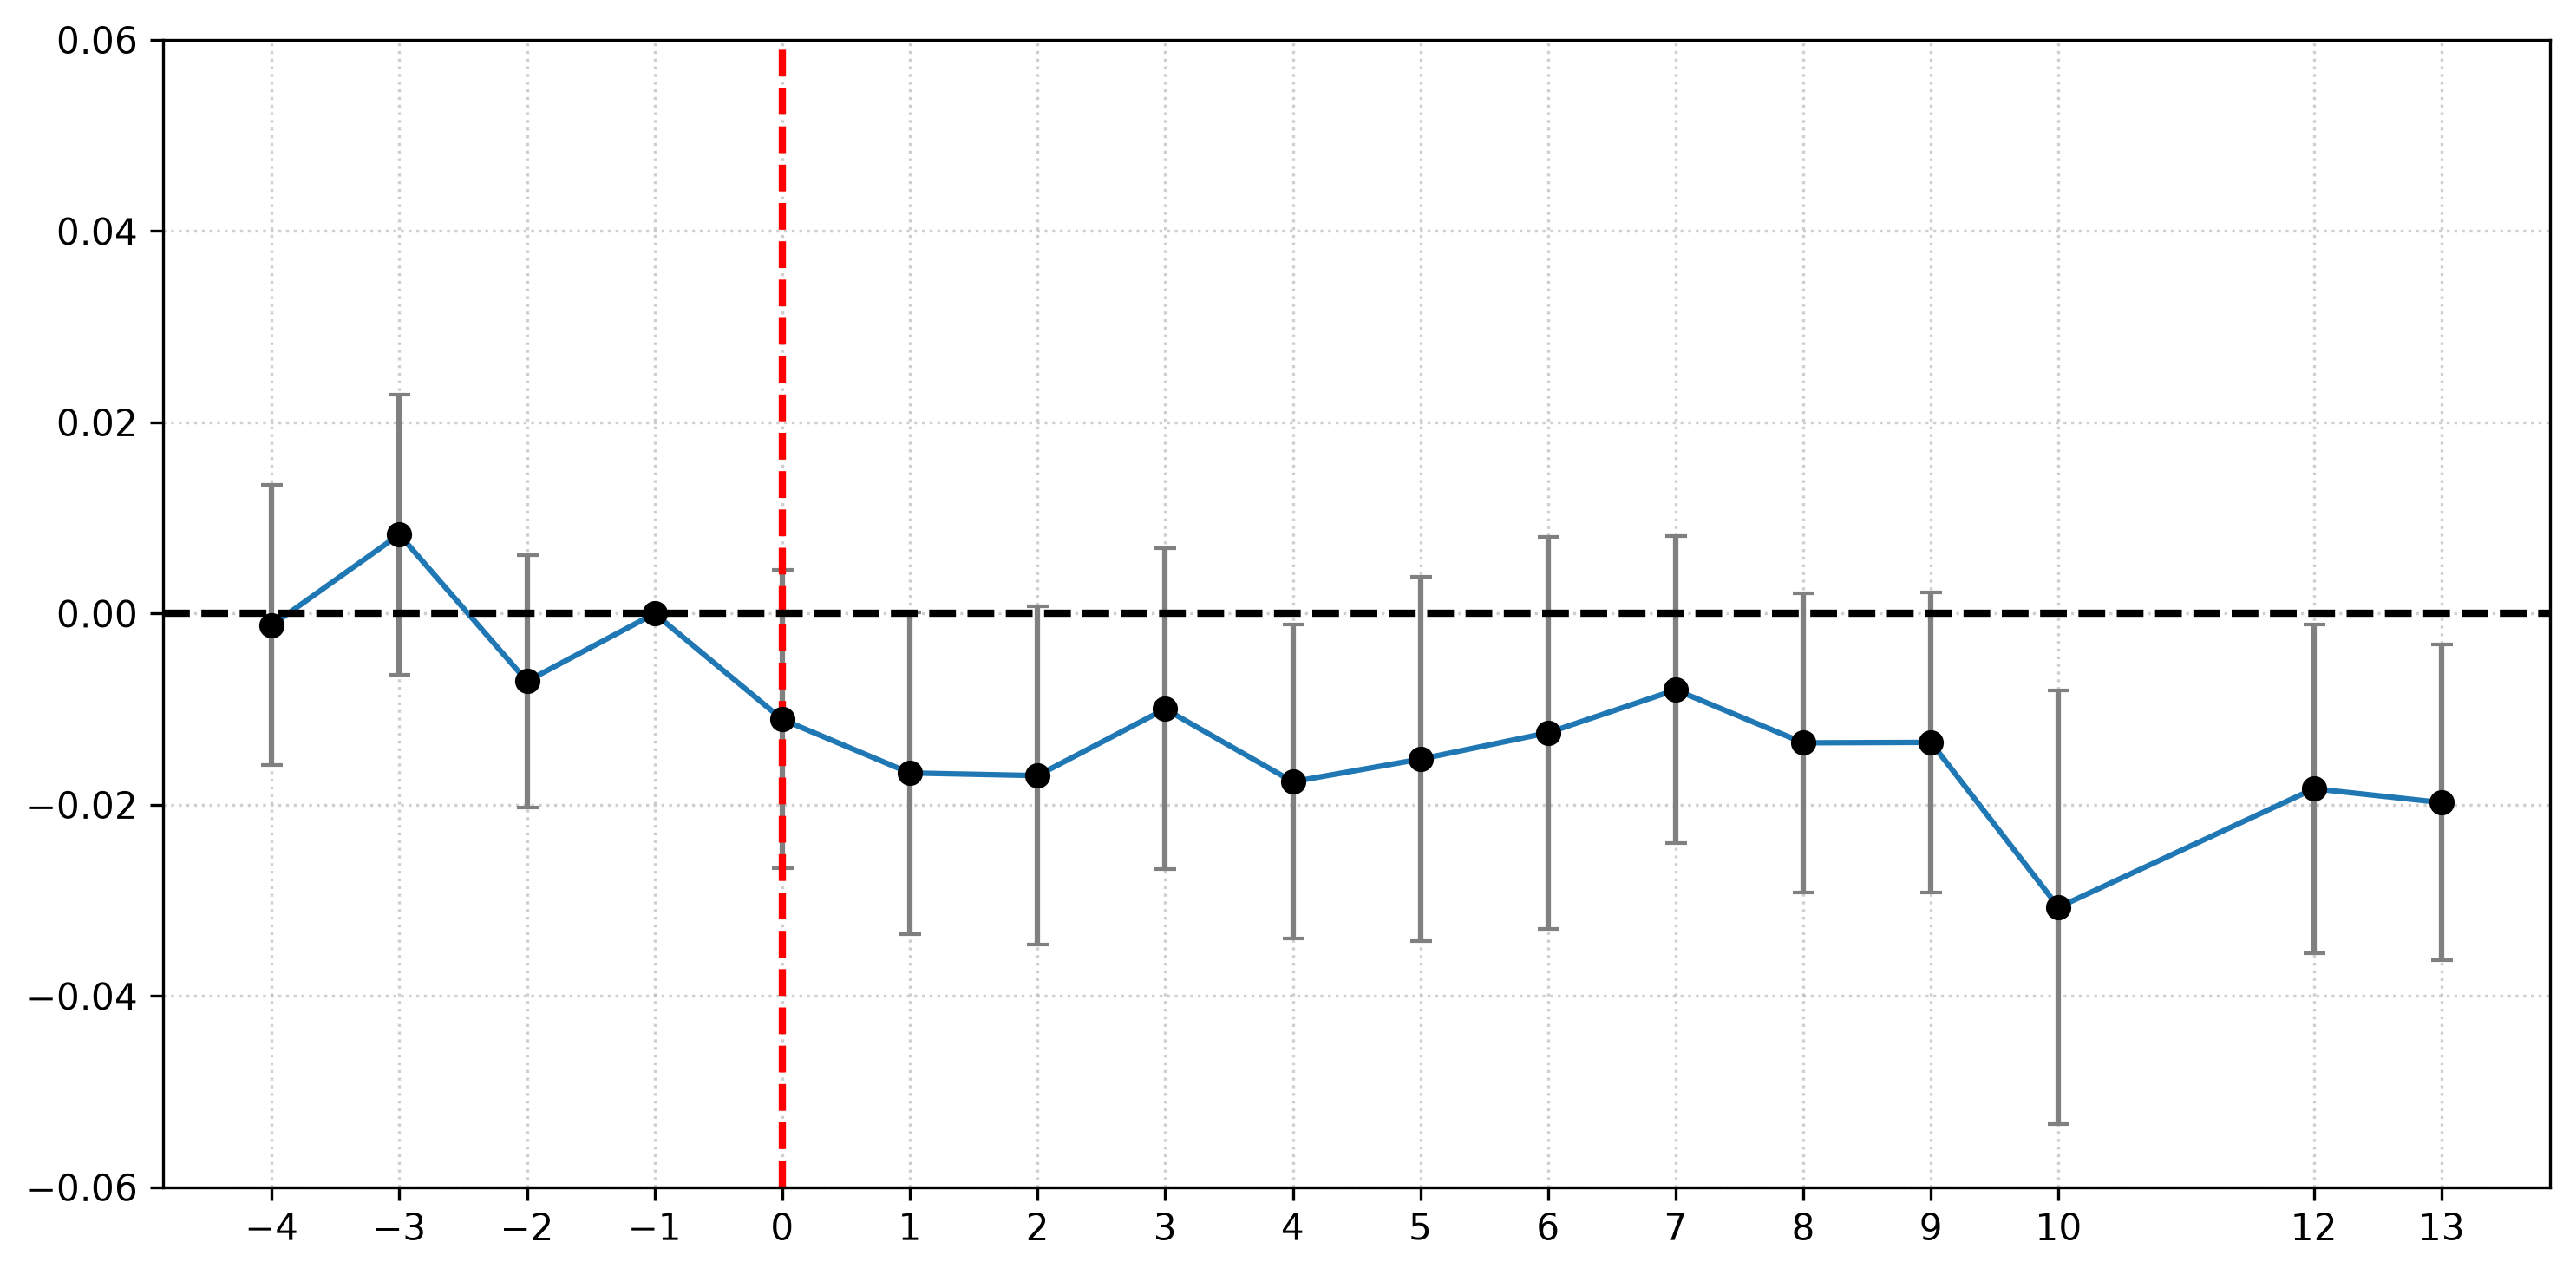

In [ ]:
# Plot event study graph
fig, ax = plt.subplots(figsize=(10, 5), dpi=300)

yerr_lower = df_res['coef'] - df_res['lower']
yerr_upper = df_res['upper'] - df_res['coef']

ax.errorbar(
    x=df_res['quarter'],
    y=df_res['coef'],
    yerr=np.asanyarray([yerr_lower, yerr_upper]),
    fmt='o',               # Circular markers for points
    color='black',
    ecolor='gray',         # Gray whisker lines
    capsize=3,             # Horizontal caps on CI bars
    linestyle='None'       # Don't connect points with lines
)

ax.plot(df_res['quarter'], df_res['coef'])

ax.grid(True, linestyle=':', alpha=0.6)

ax.axvline(x=0, color='r', linestyle='--', linewidth=2)
ax.axhline(y=0, color='black', linestyle='--', linewidth=2)
ax.set_xticks(sorted(df_res['quarter'].unique()))


ax.set_ylim(-0.06,0.06)
plt.tight_layout()
plt.show()

In [ ]:
# Event study looks ok -- probably underpowered with 4 pre treatment periods

In [ ]:
# First placebo test, treatment at time -3 (-2 and -1 are post)
df_placebo1 = df_pre[(df_pre['QUARTER'] < 0)]
df_placebo1['POST'] = (df_placebo1['QUARTER'] > -3).astype(int)
placebo_formla1 = 'Y_SHARE ~ POST:beta_z + EntityEffects + TimeEffects'

placebo_mod1 = PanelOLS.from_formula(placebo_formla1, data=df_placebo1, weights=df_placebo1['N'])
res = placebo_mod1.fit(cov_type='clustered', cluster_entity=True, cluster_time=True)
print(res.summary)


                          PanelOLS Estimation Summary                           
Dep. Variable:                Y_SHARE   R-squared:                        0.0016
Estimator:                   PanelOLS   R-squared (Between):              0.0020
No. Observations:                1428   R-squared (Within):               0.0011
Date:                Tue, Jul 28 2026   R-squared (Overall):              0.0020
Time:                        02:03:49   Log-likelihood                    3611.6
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      1.7053
Entities:                         357   P-value                           0.1919
Avg Obs:                       4.0000   Distribution:                  F(1,1067)
Min Obs:                       4.0000                                           
Max Obs:                       4.0000   F-statistic (robust):             1.2401
                            

In [ ]:
# Second placebo test, treatment at time -2 (-1 is post)
df_placebo2 = df_pre[(df_pre['QUARTER'] < 0)]
df_placebo2['POST'] = (df_placebo1['QUARTER'] > -2).astype(int)
placebo_formla2 = 'Y_SHARE ~ POST:beta_z + EntityEffects + TimeEffects'

placebo_mod2 = PanelOLS.from_formula(placebo_formla2, data=df_placebo2, weights=df_placebo2['N'])
res = placebo_mod2.fit(cov_type='clustered', cluster_entity=True, cluster_time=True)
print(res.summary)


                          PanelOLS Estimation Summary                           
Dep. Variable:                Y_SHARE   R-squared:                     6.558e-06
Estimator:                   PanelOLS   R-squared (Between):           7.361e-05
No. Observations:                1428   R-squared (Within):            2.898e-07
Date:                Tue, Jul 28 2026   R-squared (Overall):           7.248e-05
Time:                        02:26:33   Log-likelihood                    3610.5
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      0.0070
Entities:                         357   P-value                           0.9333
Avg Obs:                       4.0000   Distribution:                  F(1,1067)
Min Obs:                       4.0000                                           
Max Obs:                       4.0000   F-statistic (robust):             0.0107
                            

In [60]:
# Third placebo test, treatment at time -4 (-1, -2, and -3 are post)
df_placebo3 = df_pre[(df_pre['QUARTER'] < 0)]
df_placebo3['POST'] = (df_placebo3['QUARTER'] >= -3).astype(int)
placebo_formla3 = 'Y_SHARE ~ POST:beta_z + EntityEffects + TimeEffects'

placebo_mod3 = PanelOLS.from_formula(placebo_formla3, data=df_placebo3, weights=df_placebo3['N'])
res = placebo_mod3.fit(cov_type='clustered', cluster_entity=True, cluster_time=True)
print(res.summary)

                          PanelOLS Estimation Summary                           
Dep. Variable:                Y_SHARE   R-squared:                     5.974e-05
Estimator:                   PanelOLS   R-squared (Between):             -0.0007
No. Observations:                1428   R-squared (Within):               0.0001
Date:                Tue, Jul 28 2026   R-squared (Overall):             -0.0007
Time:                        03:05:59   Log-likelihood                    3610.5
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      0.0637
Entities:                         357   P-value                           0.8007
Avg Obs:                       4.0000   Distribution:                  F(1,1067)
Min Obs:                       4.0000                                           
Max Obs:                       4.0000   F-statistic (robust):             0.0852
                            

In [ ]:
# All three placebos pass, we are not picking up differential trends within the pre-treatment area

In [62]:
# Main analysis at the half year level
df_did = panel_h.set_index(['OCC', 'HALF_YEAR'], drop=False)
df_did['POST'] = (df_did['HALF_YEAR'] >= 0).astype(int)

did_formula = 'Y_SHARE ~ POST:beta_z + EntityEffects + TimeEffects'
did_mod = PanelOLS.from_formula(did_formula, data=df_did, weights=df_did['N'])
res = did_mod.fit(cov_type='clustered', cluster_entity=True, cluster_time=True)
print(res.summary)

                          PanelOLS Estimation Summary                           
Dep. Variable:                Y_SHARE   R-squared:                        0.0057
Estimator:                   PanelOLS   R-squared (Between):              0.0067
No. Observations:                3213   R-squared (Within):               0.0056
Date:                Tue, Jul 28 2026   R-squared (Overall):              0.0067
Time:                        03:09:06   Log-likelihood                    8262.7
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      16.433
Entities:                         357   P-value                           0.0001
Avg Obs:                       9.0000   Distribution:                  F(1,2847)
Min Obs:                       9.0000                                           
Max Obs:                       9.0000   F-statistic (robust):             12.592
                            

In [ ]:
# Secondary analysis: since we proved trends at quarter level
# We need to show that coefficient holds -- biannual has much higher effective N
# So significance may not hold
df_did_q = panel_q.set_index(['OCC', 'QUARTER'], drop=False)
df_did_q['POST'] = (df_did_q['QUARTER'] >= 0).astype(int)

didq_formula = 'Y_SHARE ~ POST:beta_z + EntityEffects + TimeEffects'
didq_mod = PanelOLS.from_formula(didq_formula, data=df_did_q, weights=df_did_q['N'])
res = didq_mod.fit(cov_type='clustered', cluster_entity=True, cluster_time=True)
print(res.summary)

# Turns out both hold


                          PanelOLS Estimation Summary                           
Dep. Variable:                Y_SHARE   R-squared:                        0.0035
Estimator:                   PanelOLS   R-squared (Between):              0.0065
No. Observations:                6069   R-squared (Within):               0.0035
Date:                Tue, Jul 28 2026   R-squared (Overall):              0.0064
Time:                        03:08:42   Log-likelihood                 1.413e+04
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      20.241
Entities:                         357   P-value                           0.0000
Avg Obs:                       17.000   Distribution:                  F(1,5695)
Min Obs:                       17.000                                           
Max Obs:                       17.000   F-statistic (robust):             10.491
                            